# Lab 3 — Millions of TVs, Who Is Watching?
Name: Valentyna Tkachenko | Group: КМ-41

## Setup

In [16]:
!pip install kagglehub -q
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/4")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


In [17]:
import numpy as np

SIX = pd.Timedelta(hours=6)
TEN = ["CBS", "NBC", "ABC", "FOX", "FNC", "FX", "BRAVO", "HGTV", "FOOD", "HIST"]
BIG = ["CBS", "NBC", "ABC", "FOX", "FNC"]

def to_eastern(s):
    return pd.to_datetime(s, utc=True).dt.tz_convert("America/New_York").dt.tz_localize(None)

acr = acr_sessions
acr["start_et"] = to_eastern(acr["start_utc"])
acr["end_et"] = to_eastern(acr["end_utc"])
acr["broadcast_date"] = (acr["start_et"] - SIX).dt.normalize()
acr["hours"] = (acr["end_et"] - acr["start_et"]).dt.total_seconds() / 3600

kept = acr[acr["hours"] * 60 >= 1].copy()

intab = kept[["tv_id", "broadcast_date"]].drop_duplicates()
tvs_intab_day = intab.groupby("broadcast_date").size()

for df in (programs, viewings):
    for col in ("start_ts", "end_ts"):
        df[col] = pd.to_datetime(df[col]).astype("datetime64[ns]")
programs["broadcast_date"] = pd.to_datetime(programs["broadcast_date"]).astype("datetime64[ns]")
daily_weights["broadcast_date"] = pd.to_datetime(daily_weights["broadcast_date"]).astype("datetime64[ns]")
kept["broadcast_date"] = kept["broadcast_date"].astype("datetime64[ns]")
FIRST, LAST = kept["broadcast_date"].min(), kept["broadcast_date"].max()
dw2 = daily_weights[daily_weights["broadcast_date"].between(FIRST, LAST)]
panel_hh = dw2[dw2["resp_type"] == "H"].groupby("respondent_id")["weight"].mean().rename("avg_weight").reset_index()

print("Broadcast days:", FIRST.date(), "to", LAST.date())
print("Panel households in-tab in these two weeks:", len(panel_hh))

Broadcast days: 2024-10-14 to 2024-10-27
Panel households in-tab in these two weeks: 4111


## Task 1.1 — Five questions

**Answer:**

| Question | `acr_sessions` (smart-TV feed) | Lab 1 `viewings` (panel) |
|---|---|---|
| **Grain** | One session of continuous viewing of one thing on one TV (a device), timed to the second. | One session of one person (or of the household's TV set, H rows) on one network. |
| **Key** | `session_id`; the TV is `tv_id`; it links to households only through `hashed_ip`. | `viewing_id`; `respondent_id` (household number + person digits) links to `daily_weights` and `viewer_attributes`. |
| **Coverage** | 29,940 opted-in smart TVs, one per home, Oct 14–27, 2024; any US network plus apps, DVR and unrecognized ("unknown") time. | About 4,000 recruited homes, every person and every TV set in them, all of October 2024; only the ten networks, live viewing only. |
| **Weight** | None: every TV counts once, so the numbers are unweighted. | A daily weight for every household and person, projecting to 125.8M US TV households and 317.3M persons. |
| **Provenance** | Passive ACR: the TV maker fingerprints the screen and matches it against a library of live feeds; homes opt in through the TV's terms; who lives there comes from a compiled and modeled consumer file joined by hashed IP. | A recruited panel with people meters (each person presses a button), weighted by the measurement service to the US universe (currency-style). |

**Biggest difference: weight.** The panel is a designed sample weighted to represent all US homes and people. The smart-TV feed is a convenience sample of whoever bought this brand and opted in, with no weights and no people, so its size alone says nothing about whom it represents. (Sources: Lecture 4, "five questions for every dataset"; Lab 3 handout, section 2.)

## Task 1.2 — Size and shape

In [18]:
raw_tv_days = acr[["tv_id", "broadcast_date"]].drop_duplicates().shape[0]

print("TVs:", acr["tv_id"].nunique())
print("Sessions:", len(acr))
print("Broadcast days:", acr["broadcast_date"].nunique())
print("Average TVs in-tab per day:", round(tvs_intab_day.mean(), 1))
print("Hours per TV per day, raw:", f"{acr['hours'].sum() / raw_tv_days:.2f}")
print("Hours per TV per day, after edit rule:", f"{kept['hours'].sum() / len(intab):.2f}")
print("Share of sessions dropped:", round(1 - len(kept) / len(acr), 3))
print()
print("Share of session hours dropped by the edit rule:", round(1 - kept["hours"].sum() / acr["hours"].sum(), 3))

TVs: 29940
Sessions: 6392981
Broadcast days: 14
Average TVs in-tab per day: 29074.1
Hours per TV per day, raw: 4.74
Hours per TV per day, after edit rule: 4.70
Share of sessions dropped: 0.299

Share of session hours dropped by the edit rule: 0.007


## Task 1.3 — What the TV could not see

In [19]:
by_type = (kept.groupby("session_type")["hours"].sum() / kept["hours"].sum()).sort_values(ascending=False)
by_input = (kept.groupby("input_source")["hours"].sum() / kept["hours"].sum()).sort_values(ascending=False)
unknown = kept[kept["session_type"] == "unknown"]
unknown_by_input = (unknown.groupby("input_source")["hours"].sum() / unknown["hours"].sum()).sort_values(ascending=False)

display(by_type.round(3).rename("share_of_hours").to_frame())   # table: share of hours by session_type
display(by_input.round(3).rename("share_of_hours").to_frame())   # table: share of hours by input_source
display(unknown_by_input.round(3).rename("share_of_unknown_hours").to_frame())
print("Share of TV-on hours unknown (%):", round(by_type["unknown"] * 100, 1))

,share_of_hours
session_type,
unknown,0.396
live,0.322
app,0.257
dvr,0.025


,share_of_hours
input_source,
built_in_app,0.307
cable_box,0.276
streaming_device,0.231
antenna,0.086
satellite_box,0.076
game_or_disc,0.024


,share_of_unknown_hours
input_source,
streaming_device,0.517
cable_box,0.229
antenna,0.079
satellite_box,0.063
game_or_disc,0.061
built_in_app,0.051


Share of TV-on hours unknown (%): 39.6


**Answer:** In this feed 39.6% of TV-on hours are "unknown", against 66% in LG's real sample for October 1–8, 2025. A real feed can have even more unknown time because ACR only recognizes what is in its reference library of live feeds (Lecture 4). Anything that is not in the library, or that does not look like the live broadcast on screen, cannot be matched: smaller or local channels and FAST channels the vendor does not ingest, on-demand and DVR playback outside the matching window, pictures covered by menus or picture-in-picture, and content from external devices that the TV maker is not allowed to fingerprint. This synthetic feed was also built to recognize every live network cleanly, while a real one has more noise and gaps.

Two kinds of viewing that end up as unknown: (1) streaming through an external device, such as Netflix or YouTube on a Roku, Fire TV or Apple TV box. Here 52% of all unknown hours come from `streaming_device`. (2) Video games and discs (`game_or_disc`), plus video on demand played from a cable box, which has no live feed to match. (Sources: Lecture 4, "ACR and its errors" and "what ACR cannot see"; Lab 3 handout, section 2.)

## Task 2.1 — Match

In [20]:
tv_ip = acr.drop_duplicates("tv_id")[["tv_id", "hashed_ip"]]
hh_per_ip = hh_attributes.groupby("hashed_ip")["household_id"].nunique()
tv_ip["n_households"] = tv_ip["hashed_ip"].map(hh_per_ip).fillna(0).astype(int)
tv_ip["match"] = np.select([tv_ip["n_households"] == 1, tv_ip["n_households"] > 1],
                           ["one", "shared"], default="none")
share = tv_ip["match"].value_counts(normalize=True) * 100

print("Matched to one household (%):", round(share.get("one", 0), 1))
print("Shared IP, unresolved (%):", round(share.get("shared", 0), 1))
print("Not matched (%):", round(share.get("none", 0), 1))

Matched to one household (%): 65.2
Shared IP, unresolved (%): 11.8
Not matched (%): 22.9


**Answer:** Only 65.2% of the TVs can be linked to exactly one household. 11.8% sit behind an IP address shared by several households, and 22.9% have an IP that is not in the household file at all. So about a third of the footprint has no household attributes.

An IP address is a weak key because it identifies a network connection, not a household (Lecture 4, "IP linkage"). Several homes can share one IP: apartment buildings, dorms and offices behind one router, and internet providers that put many customers behind one public address (carrier-grade NAT). The same home also changes its IP over time, because providers reassign dynamic addresses, so the IP in the consumer file may be stale. VPNs, mobile hotspots and moves add more errors. Each mismatch either loses the TV (no match) or attaches it to the wrong household's attributes.

## Task 2.2 — Profile

In [21]:
INCOME3 = {"Under $25k": "Under $50k", "$25k-$50k": "Under $50k",
           "$50k-$75k": "$50-100k", "$75k-$100k": "$50-100k",
           "$100k-$150k": "$100k+", "$150k+": "$100k+"}

matched = tv_ip[tv_ip["match"] == "one"].merge(hh_attributes, on="hashed_ip")
matched["income3"] = matched["income_band"].map(INCOME3)

codes = attributes.set_index("attr_id")["attr_name"]
hh_codes = viewer_attributes[viewer_attributes["respondent_id"].isin(panel_hh["respondent_id"])].copy()
hh_codes["name"] = hh_codes["attr_id"].map(codes)
region = hh_codes[hh_codes["attr_id"].between(841, 844)].drop_duplicates("respondent_id").set_index("respondent_id")["name"]
income = hh_codes[hh_codes["attr_id"].between(811, 816)].drop_duplicates("respondent_id").set_index("respondent_id")["name"]
panel_hh["region"] = panel_hh["respondent_id"].map(region)
panel_hh["income3"] = panel_hh["respondent_id"].map(income).map(INCOME3)

rows = []
for var, label in [("region", "Region"), ("income3", "Income")]:
    fp = matched[var].value_counts(normalize=True)
    pn = panel_hh.groupby(var)["avg_weight"].sum() / panel_hh["avg_weight"].sum()
    for g in pn.index:
        rows.append({"variable": label, "group": g, "footprint_share": fp.get(g, 0), "panel_share": pn[g]})
profile = pd.DataFrame(rows)
profile["index"] = profile["footprint_share"] / profile["panel_share"] * 100
order = ["Northeast", "Midwest", "South", "West", "Under $50k", "$50-100k", "$100k+"]
profile = profile.set_index("group").loc[order].reset_index()
profile.round({"footprint_share": 3, "panel_share": 3, "index": 0})   # table: group, footprint share, panel share, index

,group,variable,footprint_share,panel_share,index
0,Northeast,Region,0.150,0.170,88.0
1,Midwest,Region,0.201,0.210,96.0
2,South,Region,0.383,0.379,101.0
3,West,Region,0.266,0.241,110.0
4,Under $50k,Income,0.259,0.361,72.0
5,$50-100k,Income,0.320,0.289,111.0
6,$100k+,Income,0.421,0.350,120.0


**Answer:** The footprint is skewed toward richer homes. Households with $100k+ are over-represented (index 120) and $50–100k slightly (111), while homes under $50k are strongly under-represented (index 72): they are 36% of US TV households but only 26% of the matched footprint. By region the skew is smaller: the West is over-represented (110), the Northeast under-represented (88), and the Midwest and South are close to their US shares (96 and 101).

One reason: to be in this footprint a home must own a recent smart TV of this one brand, connect it to broadband, and leave data sharing switched on. Higher-income homes buy new TVs more often and are more likely to have broadband, while lower-income homes keep older, non-connected sets. The brand's market share also differs by region. Matching adds to the skew: single-family homes (more often higher-income) have their own IP address, while apartment buildings share one and drop out as unresolved (Task 2.1). (Sources: Lecture 4, "panels vs big data" and "IP linkage"; Lab 3 handout, section 2.)

## Task 2.3 — Ratings

In [22]:
live = kept[kept["session_type"] == "live"]

def tv_rating(tel):
    s = live[(live["network_code"] == tel.network_code)
             & (live["start_et"] < tel.end_ts) & (live["end_et"] > tel.start_ts)]
    ov = (s["end_et"].clip(upper=tel.end_ts) - s["start_et"].clip(lower=tel.start_ts)).dt.total_seconds() / 60
    watched = (ov.groupby(s["tv_id"]).sum() >= 1).sum()
    return watched, tvs_intab_day[tel.broadcast_date]

ref = reference_ratings.merge(programs[["telecast_id", "network_code", "program_name", "broadcast_date",
                                        "start_ts", "end_ts"]], on="telecast_id")
out = [tv_rating(t) for t in ref.itertuples()]
ref["tvs_watched"] = [w for w, _ in out]
ref["tvs_intab"] = [n for _, n in out]
ref["tv_hh_rating"] = ref["tvs_watched"] / ref["tvs_intab"] * 100
ref["ratio"] = ref["tv_hh_rating"] / ref["hh_rating"]
ref["date"] = ref["broadcast_date"].dt.strftime("%Y-%m-%d")
ratings = ref[["network_code", "program_name", "date", "tv_hh_rating", "hh_rating", "ratio"]].rename(
    columns={"hh_rating": "reference_hh_rating"}).sort_values("ratio", ascending=False).reset_index(drop=True)
ratings.round({"tv_hh_rating": 1, "reference_hh_rating": 1, "ratio": 3})   # table: telecast, TVs' HH rating, reference HH rating

,network_code,program_name,date,tv_hh_rating,reference_hh_rating,ratio
0,NBC,NFL Football,2024-10-27,21.2,33.1,0.641
1,FX,Grotesquerie,2024-10-16,2.3,3.5,0.641
2,FOX,MLB Postseason,2024-10-25,16.5,25.9,0.639
3,FOOD,Halloween Baking Championship,2024-10-14,1.0,1.6,0.604
4,BRAVO,The Real Housewives of New York City,2024-10-15,0.7,1.2,0.600
5,HGTV,Unsellable Houses,2024-10-16,2.1,3.7,0.568
6,CBS,NCIS,2024-10-14,5.4,10.6,0.509
7,FNC,Hannity,2024-10-16,0.8,2.3,0.359


In [23]:
print("Head of household age, matched TVs vs all households in the file:")
(pd.DataFrame({"matched_TVs": matched["head_age_band"].value_counts(normalize=True),
               "household_file": hh_attributes["head_age_band"].value_counts(normalize=True)})
 .assign(index=lambda t: t.matched_TVs / t.household_file * 100).round(3))

Head of household age, matched TVs vs all households in the file:


,matched_TVs,household_file,index
head_age_band,,,
18-34,0.196,0.188,104.402
35-49,0.348,0.292,119.391
50-64,0.263,0.251,104.844
65+,0.192,0.269,71.373


**Answer:** Every TV rating is too low: the TVs give only 36% to 64% of the reference. Part of that gap pushes all telecasts the same way: each home is measured on one smart TV, while the reference counts viewing on any set in the home (Task 3). So the useful comparison is between the telecasts.

The closest are Sunday Night Football on NBC (ratio 0.641), Grotesquerie on FX (0.641) and the World Series on FOX (0.639): sports and a young-skewing FX drama. The furthest off are Hannity on Fox News (0.359, barely a third of the reference), then NCIS on CBS (0.509) and Unsellable Houses on HGTV (0.568): the programs with the oldest audiences.

This fits the profile. The footprint has too few lower-income homes (index 72) and too few homes with a head aged 65+ (index 71 against the vendor's whole household file), and those are exactly the homes that watch Fox News and CBS most. So the older a program's audience, the more of it the footprint misses, and the lower its rating comes out. The bias is not the same for every program, so it cannot be fixed by one multiplier; it needs weighting (Lab 4). (Sources: Lab 3 handout, Task 2 hint; Lecture 4, "panels vs big data".)

## Task 3.1 — Hours per home

In [24]:
live10 = live[live["network_code"].isin(TEN)]
tv_hours_day = live10["hours"].sum() / len(intab)

pv = viewings[(viewings["resp_type"] == "H") & viewings["network_code"].isin(TEN)].copy()
pv["broadcast_date"] = (pv["start_ts"] - SIX).dt.normalize()
pv = pv[pv["broadcast_date"].between(FIRST, LAST)]
pv["hours"] = (pv["end_ts"] - pv["start_ts"]).dt.total_seconds() / 3600
hh_days_w = dw2.loc[dw2["resp_type"] == "H", "weight"].sum()
panel_hours_day = (pv["hours"] * pv["weight"]).sum() / hh_days_w

print("Live hours per TV per day (ten networks):", f"{tv_hours_day:.2f}")
print("Live hours per panel household per day (ten networks):", f"{panel_hours_day:.2f}")
print()
print("TVs as a share of panel households:", round(tv_hours_day / panel_hours_day, 3))

Live hours per TV per day (ten networks): 0.87
Live hours per panel household per day (ten networks): 1.92

TVs as a share of panel households: 0.452


**Answer:** The smart TVs are much lower: 0.87 live hours per TV per day on the ten networks, against 1.92 hours per panel household, about 1.05 hours less, or only 45% of the panel figure.

The main reason is that the feed measures one TV, while the panel's household (H) rows count viewing on every set in the home. An average US home has about 2.6 TV sets, and only about 1.1 of them are of the same brand (Lecture 4). So the viewing on the bedroom or kitchen TV, or on another brand's set, never reaches this feed. Smaller reasons push the same way: live viewing that ACR fails to recognize ends up as "unknown", and the footprint has fewer of the older, lower-income homes that watch the most linear TV (Task 2.2).

## Task 3.2 — Network shares

In [25]:
shares = pd.DataFrame({
    "share_TVs": live10.groupby("network_code")["hours"].sum() / live10["hours"].sum(),
    "share_panel": (pv["hours"] * pv["weight"]).groupby(pv["network_code"]).sum() / (pv["hours"] * pv["weight"]).sum(),
}).reindex(TEN)
shares["index"] = shares["share_TVs"] / shares["share_panel"] * 100
shares.round({"share_TVs": 3, "share_panel": 3, "index": 0})   # table: network, share in TVs, share in panel

,share_TVs,share_panel,index
network_code,,,
CBS,0.182,0.196,93.0
NBC,0.214,0.206,104.0
ABC,0.196,0.187,105.0
FOX,0.201,0.194,104.0
FNC,0.085,0.110,77.0
FX,0.028,0.022,129.0
BRAVO,0.016,0.013,122.0
HGTV,0.034,0.031,110.0
FOOD,0.024,0.022,109.0


The smart-TV data overstates the younger-skewing cable networks (FX index 129, Bravo 122, HGTV 110, Food 109) and understates the older ones: Fox News (77) and CBS (93). NBC, ABC, FOX and History are close to the panel (104–105). This is the same age and income skew found in Task 2.

## Task 3.3 — What each can see

**Answer:**

**What the panel can see that this data cannot:**
1. **People, not just sets.** Each person presses a button, so the panel knows who is watching (age, sex, guests) and gives person ratings such as A18–49. The smart-TV feed only knows that a TV was on.
2. **Every set in the home and every kind of home.** It measures all TVs in the household, including other brands and older non-smart sets, and also homes that never bought a smart TV or did not opt in.
3. **A projection to the US.** Weights make its numbers stand for all 125.8M TV households and 317.3M persons; the smart-TV numbers are unweighted counts of a convenience sample.

**What this data can see that the panel's ten-network files cannot:**
1. **Everything else on the screen:** every US network (not only the ten), plus streaming apps, DVR playback and "unknown" TV-on time, and which input fed the screen (cable box, antenna, streaming device, game console).
2. **Scale and detail:** about 30,000 homes instead of about 4,000, timed to the second, so small networks and single telecasts have far less sampling error (Task 5).
3. **Local markets:** each TV has a DMA code, so viewing can be studied market by market, where the national panel is far too thin.

(Sources: Lecture 4, "what ACR cannot see" and "panels vs big data"; Lab 3 handout, section 2.)

## Task 4.1 — Daily plots

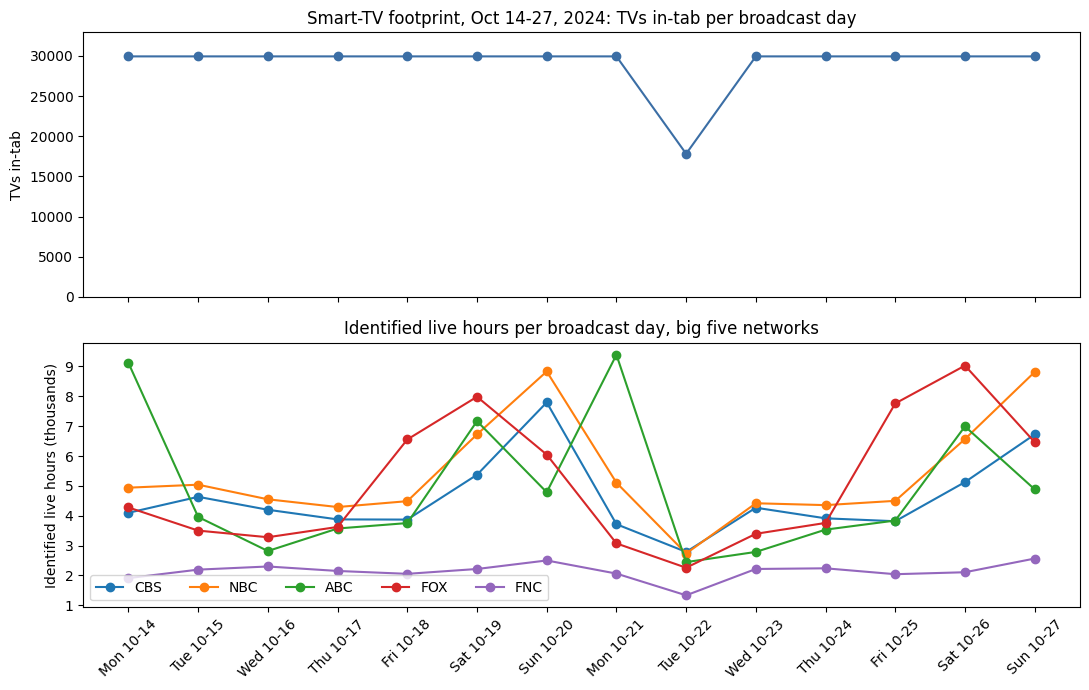

In [26]:
big_daily = (live[live["network_code"].isin(BIG)].groupby(["broadcast_date", "network_code"])["hours"].sum()
             .unstack()[BIG])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax1.plot(tvs_intab_day.index, tvs_intab_day.values, marker="o", color="#3b6ea5")
ax1.set_ylabel("TVs in-tab")
ax1.set_title("Smart-TV footprint, Oct 14-27, 2024: TVs in-tab per broadcast day")
ax1.set_ylim(0, tvs_intab_day.max() * 1.1)
for net in BIG:
    ax2.plot(big_daily.index, big_daily[net] / 1000, marker="o", label=net)
ax2.set_ylabel("Identified live hours (thousands)")
ax2.set_title("Identified live hours per broadcast day, big five networks")
ax2.legend(ncol=5)
ax2.set_xticks(big_daily.index)
ax2.set_xticklabels(big_daily.index.strftime("%a %m-%d"), rotation=45)
plt.tight_layout()
plt.show()   # plot: TVs in-tab per day; live hours per day for the big five networks

## Task 4.2 — Spike and broken day

In [27]:
stack = big_daily.stack()
spike_day, spike_net = stack.idxmax()

daily = pd.DataFrame({"tvs_intab": tvs_intab_day,
                      "hours_all": kept.groupby("broadcast_date")["hours"].sum()})
daily["hours_per_intab_tv"] = daily["hours_all"] / daily["tvs_intab"]
broken = daily["tvs_intab"].idxmin()

print("Biggest spike (date, network):", spike_day.strftime("%Y-%m-%d"), spike_net)
print("Broken day (date):", broken.strftime("%Y-%m-%d"))
print()
print("Identified live hours at the spike:", f"{stack.max():.2f}")
print("TVs in-tab on the broken day:", int(daily.loc[broken, "tvs_intab"]),
      "| on the other days:", int(daily.drop(broken)["tvs_intab"].median()))
display(daily.assign(date=daily.index.strftime("%Y-%m-%d")).set_index("date")
        .round({"hours_all": 0, "hours_per_intab_tv": 2}))

programs[(programs["network_code"] == spike_net) & (programs["broadcast_date"] == spike_day)
         & (programs["start_ts"].dt.hour >= 19)][["program_name", "episode_name", "start_ts", "end_ts"]]

Biggest spike (date, network): 2024-10-21 ABC
Broken day (date): 2024-10-22

Identified live hours at the spike: 9392.46
TVs in-tab on the broken day: 17818 | on the other days: 29940


,tvs_intab,hours_all,hours_per_intab_tv
date,,,
2024-10-14,29940,135257.0,4.52
2024-10-15,29940,133544.0,4.46
2024-10-16,29940,133116.0,4.45
2024-10-17,29940,131952.0,4.41
2024-10-18,29940,131461.0,4.39
2024-10-19,29940,158983.0,5.31
2024-10-20,29940,159162.0,5.32
2024-10-21,29940,136379.0,4.56
2024-10-22,17818,79259.0,4.45


,program_name,episode_name,start_ts,end_ts
280,Local / Syndicated Programming,None,2024-10-21 19:00:00,2024-10-21 20:00:00
281,Who Wants to Be a Millionaire,None,2024-10-21 20:00:00,2024-10-21 20:15:00
282,NFL Football,NFL Football: BAL @ TB,2024-10-21 20:15:00,2024-10-21 23:25:00
283,Local / Syndicated Programming,None,2024-10-21 23:25:00,2024-10-22 00:35:00


**Answer:** **Spike.** The biggest spike is ABC on Monday, 2024-10-21: 9,392 identified live hours, about three times a normal weekday on ABC. `programs` shows what aired: Monday Night Football, Baltimore at Tampa Bay (NFL Football: BAL @ TB, 20:15–23:25). ABC rises the same way on the previous Monday (Oct 14), FOX on Oct 25–26 (World Series and college football), and CBS and NBC on Sundays (NFL). These are real audience events.

**Broken day.** On Tuesday, 2024-10-22 only 17,818 TVs are in-tab, against 29,940 on every other day: about 40% of the footprint is missing for the whole day, in every hour and every market. Hours per in-tab TV stay normal (4.45, like other weekdays), so the audience did not change; part of the data did not arrive (a delivery or ingestion failure at the vendor). If nobody noticed, every daily total for Oct 22 (hours, impressions, live hours per network) would drop by about 40% and look like an audience collapse, and the two-week totals would be about 3% too low. A rating divided by all 29,940 TVs instead of the TVs in-tab would also be 40% too low. A rating divided by the in-tab TVs is roughly fine, but rests on fewer homes, and would be biased if the missing TVs were not random.

**What to do:** flag it, and do not use it for totals. Keep Oct 22 marked in every report, compute ratings only with that day's in-tab denominator, leave the day out of daily totals and trends (or replace it if the vendor re-delivers the missing files), and ask the vendor what happened. Silently dropping it would hide a data-quality problem; silently keeping it would distort the totals. (Source: Lab 3 handout, Task 4 hint; Lecture 4, "five questions": coverage.)

## Task 5.1 — Sampling error vs bias

In [28]:
hh_intab_day = dw2[dw2["resp_type"] == "H"].groupby("broadcast_date").size()
se = ref[ref["program_name"].isin(["NFL Football", "Hannity", "Unsellable Houses"])].copy()
p = se["hh_rating"] / 100
se["n_TVs"] = se["tvs_intab"]
se["n_panel"] = se["broadcast_date"].map(hh_intab_day)
se["se_footprint"] = np.sqrt(p * (1 - p) / se["n_TVs"]) * 100
se["se_panel"] = np.sqrt(p * (1 - p) / se["n_panel"]) * 100
se["se_panel_over_footprint"] = se["se_panel"] / se["se_footprint"]
se["tv_minus_reference"] = se["tv_hh_rating"] - se["hh_rating"]
se["gap_over_se_footprint"] = se["tv_minus_reference"].abs() / se["se_footprint"]
se[["program_name", "date", "hh_rating", "n_TVs", "n_panel", "se_footprint", "se_panel",
    "se_panel_over_footprint", "tv_minus_reference", "gap_over_se_footprint"]].round(
    {"hh_rating": 1, "se_footprint": 2, "se_panel": 2, "se_panel_over_footprint": 1,
     "tv_minus_reference": 1, "gap_over_se_footprint": 1}).reset_index(drop=True)   # table: telecast, SE footprint, SE panel, TVs' rating - reference

,program_name,date,hh_rating,n_TVs,n_panel,se_footprint,se_panel,se_panel_over_footprint,tv_minus_reference,gap_over_se_footprint
0,NFL Football,2024-10-27,33.1,29940,3898,0.27,0.75,2.8,-11.9,43.7
1,Hannity,2024-10-16,2.3,29940,3867,0.09,0.24,2.8,-1.5,17.0
2,Unsellable Houses,2024-10-16,3.7,29940,3867,0.11,0.30,2.8,-1.6,14.6


**Answer:** With about 29,900 TVs in-tab instead of about 3,900 panel households, the footprint's sampling error is about 2.8 times smaller (√(29,940/3,898) ≈ 2.8): 0.27 rating points instead of 0.75 for Sunday Night Football, 0.09 instead of 0.24 for Hannity, and 0.11 instead of 0.30 for Unsellable Houses.

But the gap between the TVs' rating and the reference is far bigger: −11.9 points for Sunday Night Football, −1.5 for Hannity and −1.6 for Unsellable Houses, which is 15 to 44 times the footprint's standard error. So the bias (one TV per home, the skew toward richer and younger homes, unmatched and opted-out homes) is the bigger error, not sampling. More data shrinks only the sampling error: SE falls with √n, but a biased sample stays biased however big it gets. Ten times more TVs from the same kind of homes would give a very precise wrong number. (Sources: Lecture 3, sampling error and "panels vs big data"; Lab 3 handout, Task 5.)

## Task 5.2 — Answer to the planner

**Answer:** From this feed, Sunday Night Football (Dallas at San Francisco, NBC, Oct 27) gets a household rating of 21.2, while the currency rating is 33.1. For tomorrow's presentation please use the currency number (33.1); if the feed is shown at all, label 21.2 as an unweighted, directional smart-TV figure, not a rating. The feed misses about a third of the audience for structural reasons, not by chance: it measures one TV per home while the average home has about 2.6 sets, and it cannot see people (who is watching, their age and sex), viewing in apps or unrecognized time, homes without this brand of smart TV or that opted out, or the 35% of TVs that do not match one household. Its homes are also richer and younger than the US (Task 2), so older-skewing programs are missed even more. On top of that, one of the 14 days (Oct 22) lost 40% of its TVs. Before using the feed for planning I would need it weighted to the US universe against the panel (Lab 4), adjusted for the other sets in the home, fused with panel persons data (for example VPVH) for demos such as A25–54, and validated against the currency on many telecasts.

## Bonus

In [29]:
snf = ref[ref["program_name"] == "NFL Football"].iloc[0]
day_w = daily_weights[daily_weights["broadcast_date"] == snf.broadcast_date]
age = (viewer_attributes[viewer_attributes["attr_id"] == 300]
       .drop_duplicates("respondent_id").set_index("respondent_id")["value"])

v = viewings[(viewings["network_code"] == snf.network_code)
             & (viewings["start_ts"] < snf.end_ts) & (viewings["end_ts"] > snf.start_ts)
             & viewings["resp_type"].isin(["H", "R", "L"])].copy()
v["overlap_min"] = (v["end_ts"].clip(upper=snf.end_ts) - v["start_ts"].clip(lower=snf.start_ts)).dt.total_seconds() / 60
watched = v.groupby(["respondent_id", "resp_type"])["overlap_min"].sum().reset_index()
watched = watched[watched["overlap_min"] >= 1].merge(day_w[["respondent_id", "weight"]], on="respondent_id")
watched["age"] = watched["respondent_id"].map(age)

hh_watched_w = watched.loc[watched["resp_type"] == "H", "weight"].sum()
a2554_watched_w = watched.loc[watched["resp_type"].isin(["R", "L"]) & watched["age"].between(25, 54), "weight"].sum()
vpvh = a2554_watched_w / hh_watched_w

persons_day = day_w[day_w["resp_type"].isin(["R", "L"])].copy()
persons_day["age"] = persons_day["respondent_id"].map(age)
univ_hh = day_w.loc[day_w["resp_type"] == "H", "weight"].sum()
univ_a2554 = persons_day.loc[persons_day["age"].between(25, 54), "weight"].sum()
a2554_rating = snf.tv_hh_rating * vpvh * univ_hh / univ_a2554

print("VPVH A25-54:", round(vpvh, 3))
print("A25-54 rating (persons):", round(a2554_rating, 1))
print()
print("TVs' HH rating used:", round(snf.tv_hh_rating, 1), "| US TV households (M):", round(univ_hh / 1e6, 1),
      "| US A25-54 persons (M):", round(univ_a2554 / 1e6, 1))
print("For comparison, A25-54 rating from the panel itself:", round(a2554_watched_w / univ_a2554 * 100, 1),
      "| with the reference HH rating instead of the TVs':", round(snf.hh_rating * vpvh * univ_hh / univ_a2554, 1))

VPVH A25-54: 0.513
A25-54 rating (persons): 11.1

TVs' HH rating used: 21.2 | US TV households (M): 125.8 | US A25-54 persons (M): 123.7
For comparison, A25-54 rating from the panel itself: 17.8 | with the reference HH rating instead of the TVs': 17.3


**Answer:** In the panel, every household that watched Sunday Night Football had on average 0.513 viewers aged 25–54 (VPVH). Applied to the TVs' household rating (21.2) and the two panel universes (125.8M TV households, 123.7M A25–54 persons), this gives an A25–54 rating of 11.1.

This assumes that a footprint home watching the game has the same number and mix of people as a panel home watching it: the same household size, the same share of 25–54 adults, and the same group viewing. It also assumes that the one smart TV stands for the whole home and that the TVs' household rating is right. That is not true here: the TVs' household rating (21.2) is far below the reference (33.1), so the estimate inherits the whole bias. With the reference household rating the same VPVH gives 17.3, close to the panel's own A25–54 rating of 17.8. Since the footprint's homes are richer and younger than average, their real VPVH may also differ from the panel's. VPVH can turn households into persons, but it cannot fix a biased household number. (Sources: Lab 3 handout, Bonus; Lab 1 rules for viewing and weights.)